# Network-based AR-iRRR vs fixAR-IRLS: continuous-EEG (Cz) HRF

This notebook summarizes the outputs of `run_model_cont_EEG_fNIRS_AR-iRRR_network-based.py` for every subject with saved betas
(`derivatives/eeg/{subject}/betas/{subject}_cont_EEG_cz_3-stage_{AR-iRRR,fixAR-IRLS}-network_Hp_betas.pkl`).
It only reads the saved results; nothing is refit.

The parcels are split into networks (parcel name before the first `_`), and each network is fit separately:

| Model | Noise model | Fit |
|---|---|---|
| **AR-iRRR** | one spectral-whitening kernel per network, from the OLS residuals of that network's parcels, applied to the network's `Y` and to `X` | iRRR on the network's parcels; λ₁ = smallest penalty that gives rank 2 (rank ≤ number of parcels) |
| **fixAR-IRLS** | the **same** per-network whitened (and `Y_scale`-scaled) `Y` and `X` | robust IRLS per parcel (Tukey biweight, c = 4.685) |

So within a network, the two models differ only in the fit (joint low-rank vs independent per parcel).

The HRF is the response of HbO to the continuous Cz EEG regressor at delays 0–15 s, reconstructed from the 15 B-spline coefficients (`betas_bspline · basis_da`). There is no pre-onset period, so no baseline correction is applied.

Contents:
1. Load results
2. Fit summary: λ₁ per network, `Y_scale`
3. HRF at the plot parcel
4. Group HRF of every network
5. Agreement between models per network (shape and amplitude)
6. fixAR-IRLS F test: is there an EEG effect?
7. Summary

In [1]:
%matplotlib inline
import os, sys, glob, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.insert(0, os.getcwd())
from params_setting import project_path, get_betas_path, get_stats_path

plot_parcel = 'DefaultA_PFCd_1_LH'   # parcel shown in section 3 (select_parcel of the AR-iRRR script)
select_chromo = 'HbO'
eeg_reg_type = 'cont_EEG_cz_3-stage'
hp_flag = 'Hp'
models = ['AR-iRRR', 'fixAR-IRLS']
model_names = {m: f'{eeg_reg_type}_{m}-network_{hp_flag}' for m in models}
colors = {'AR-iRRR': 'C2', 'fixAR-IRLS': 'C3'}   # same as summary_cmp_AR-IRLS_fixAR-IRLS_AR-iRRR.ipynb
len_delay = 15     # s, delay axis of the HRF
t_step = 0.05      # s, resolution of the reconstructed HRF (the saved basis is at the 500 Hz EEG rate)
to_uM = 1e6

eeg_der_dir = os.path.join(project_path, 'derivatives', 'eeg')
fig_dir = os.path.join(eeg_der_dir, 'HRF_surf', 'group', f'{eeg_reg_type}_AR-iRRR_vs_fixAR-IRLS-network_{hp_flag}')
os.makedirs(fig_dir, exist_ok=True)

subjects = sorted(
    os.path.basename(os.path.dirname(os.path.dirname(f))).split('_')[0]
    for f in glob.glob(os.path.join(eeg_der_dir, 'sub-*', 'betas', f'sub-*_{model_names["AR-iRRR"]}_betas.pkl')))
subjects = [s for s in subjects
            if os.path.exists(get_betas_path(os.path.join(eeg_der_dir, s, f'{s}_{model_names["fixAR-IRLS"]}')))]

res = {}
for s in subjects:
    res[s] = {}
    for m in models:
        prefix = os.path.join(eeg_der_dir, s, f'{s}_{model_names[m]}')
        with open(get_betas_path(prefix), 'rb') as f:
            b = pickle.load(f)
        with open(get_stats_path(prefix), 'rb') as f:
            st = pickle.load(f)
        basis = b['basis_da']
        step = int(round(t_step * len(basis.regressor) / len_delay))
        basis = basis.isel(regressor=slice(None, None, step))
        hrf = (b['betas_bspline'].sel(chromo=select_chromo) @ basis).rename(regressor='time')   # parcel x time (M)
        hrf = hrf.assign_coords(time=np.arange(len(basis.regressor)) * step * len_delay / len(b['basis_da'].regressor))
        res[s][m] = {'hrf': hrf, 'stats': st}

r0 = res[subjects[0]]['AR-iRRR']
hrf_t = r0['hrf'].time.values
parcels = r0['hrf'].parcel.values
network_of = pd.Series(r0['hrf'].network.values, index=parcels)
networks = list(dict.fromkeys(network_of.values))
assert all(np.array_equal(res[s][m]['hrf'].parcel.values, parcels) for s in subjects for m in models), 'parcel sets differ'
print(f"{len(subjects)} subjects: {subjects}")
print(f"{len(parcels)} parcels in {len(networks)} networks:", network_of.value_counts()[networks].to_dict())
print(f"HRF: {len(hrf_t)} samples, {hrf_t[0]:.2f}-{hrf_t[-1]:.2f} s")

6 subjects: ['sub-670', 'sub-695', 'sub-721', 'sub-723', 'sub-726', 'sub-730']
417 parcels in 17 networks: {'ContA': 31, 'ContB': 36, 'ContC': 10, 'DefaultA': 28, 'DefaultB': 38, 'DefaultC': 5, 'DorsAttnA': 37, 'DorsAttnB': 32, 'LimbicA': 3, 'LimbicB': 5, 'SalVentAttnA': 26, 'SalVentAttnB': 22, 'SomMotA': 53, 'SomMotB': 27, 'TempPar': 18, 'VisCent': 33, 'VisPeri': 13}
HRF: 300 samples, 0.00-14.95 s


## 2. Fit summary
- **λ₁** (AR-iRRR) for each subject and network. Small networks need a smaller λ₁ to reach rank 2, because the iRRR weight grows with √(number of parcels).
- **`Y_scale`** is the std of the network's whitened `Y` (M); it is shared by both models within a network.

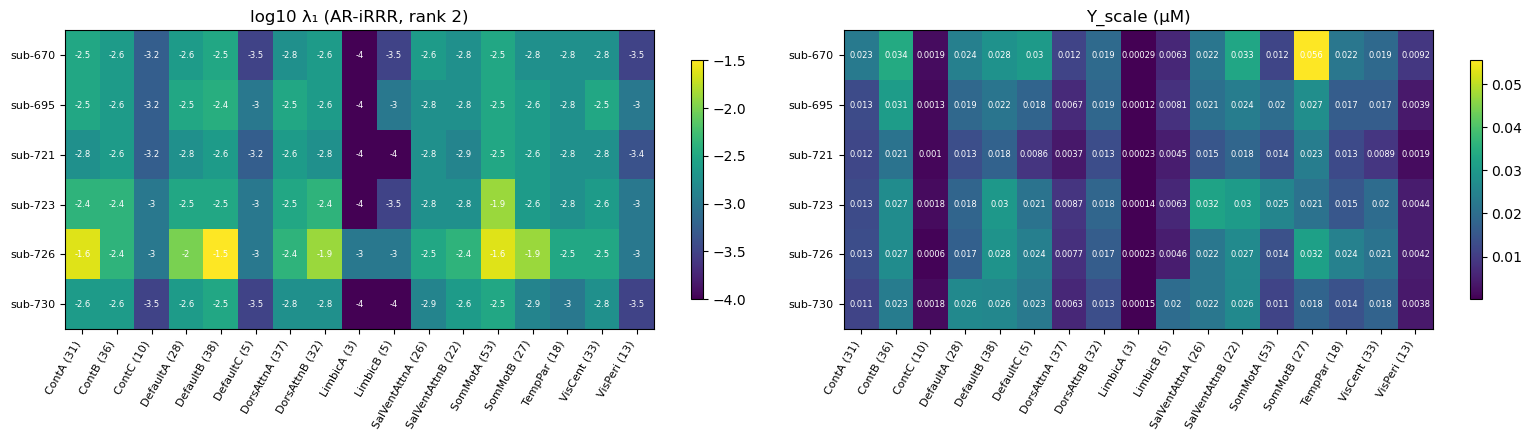

rank != 2 (subject, network): []


In [2]:
lam = pd.DataFrame({s: res[s]['AR-iRRR']['stats']['irrr_lam1'] for s in subjects}).T[networks]
rank = pd.DataFrame({s: res[s]['AR-iRRR']['stats']['rank'] for s in subjects}).T[networks]
yscale = pd.DataFrame({s: res[s]['AR-iRRR']['stats']['Y_scale'] for s in subjects}).T[networks]
n_parcel = network_of.value_counts()[networks]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for ax, df, title in [(axes[0], np.log10(lam.astype(float)), 'log10 λ₁ (AR-iRRR, rank 2)'),
                      (axes[1], yscale.astype(float) * to_uM, 'Y_scale (µM)')]:
    im = ax.imshow(df.values, aspect='auto', cmap='viridis')
    ax.set_xticks(range(len(networks)), [f'{n} ({n_parcel[n]})' for n in networks], rotation=60, ha='right', fontsize=8)
    ax.set_yticks(range(len(subjects)), subjects, fontsize=8)
    for i in range(df.shape[0]):
        for j in range(df.shape[1]):
            ax.text(j, i, f'{df.values[i, j]:.2g}', ha='center', va='center', fontsize=6, color='w')
    fig.colorbar(im, ax=ax, shrink=0.8)
    ax.set_title(title)
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, 'fit_summary.png'), dpi=150)
plt.show()
print('rank != 2 (subject, network):', [(s, n) for s in subjects for n in networks if rank.loc[s, n] != min(2, n_parcel[n])])

## 3. HRF at the plot parcel

**Top left:** group mean ± SEM across subjects for both models. **Top right:** each subject's AR-iRRR HRF against its fixAR-IRLS HRF. **Bottom:** each subject's HRF for each model.

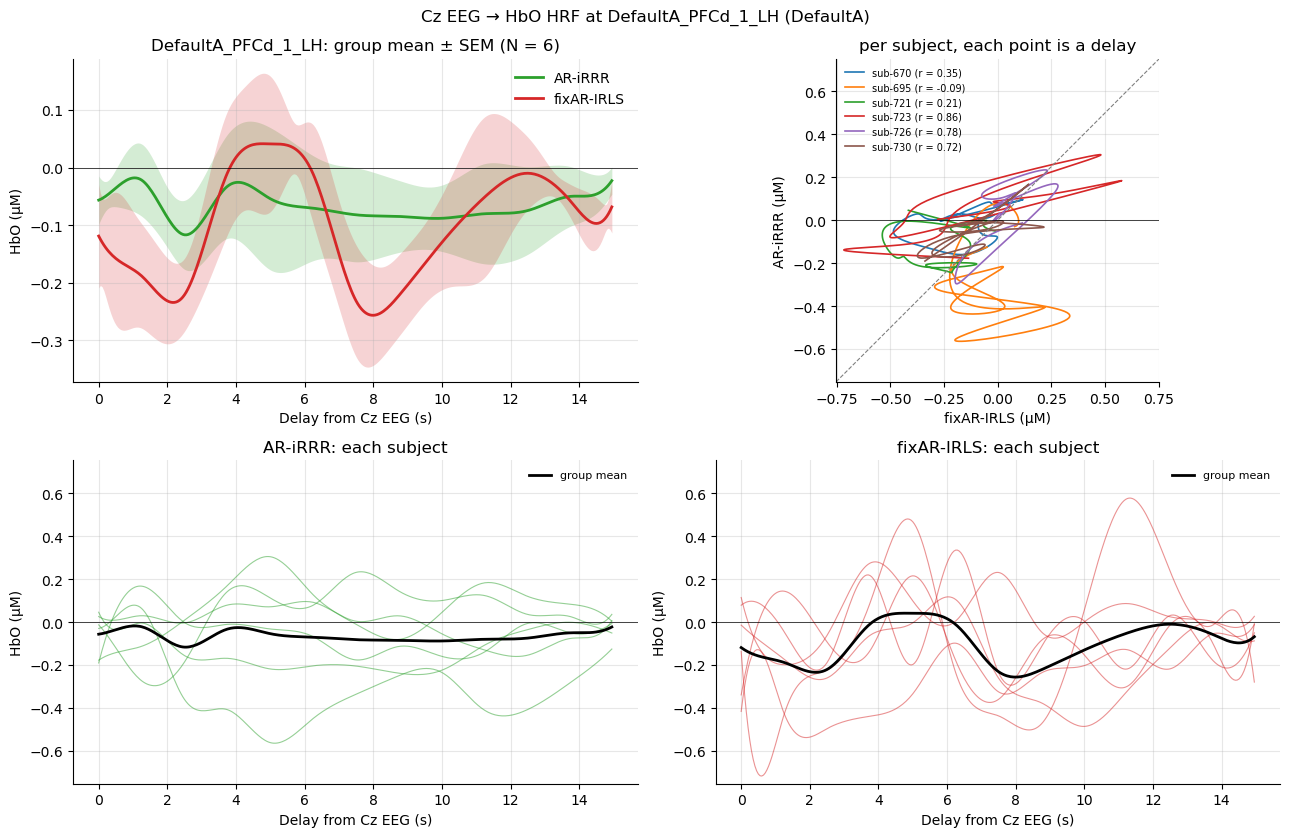

In [3]:
def parcel_hrf(m, p):
    return np.stack([res[s][m]['hrf'].sel(parcel=p).values for s in subjects]) * to_uM   # subject x time (µM)

def plot_mean_sem(ax, h, m, label=None):
    mu, sem = h.mean(0), h.std(0, ddof=1) / np.sqrt(len(h))
    ax.fill_between(hrf_t, mu - sem, mu + sem, color=colors[m], alpha=0.2, lw=0)
    ax.plot(hrf_t, mu, color=colors[m], lw=2, label=label or m)

def style(ax):
    ax.axhline(0, color='k', lw=0.5)
    ax.grid(alpha=0.3); ax.spines[['top', 'right']].set_visible(False)

h_p = {m: parcel_hrf(m, plot_parcel) for m in models}
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
ax = axes[0, 0]
for m in models:
    plot_mean_sem(ax, h_p[m], m)
ax.set_title(f'{plot_parcel}: group mean ± SEM (N = {len(subjects)})')
ax.legend(frameon=False)
ax = axes[0, 1]
for i, s in enumerate(subjects):
    r = np.corrcoef(h_p['AR-iRRR'][i], h_p['fixAR-IRLS'][i])[0, 1]
    ax.plot(h_p['fixAR-IRLS'][i], h_p['AR-iRRR'][i], lw=1.2, label=f'{s} (r = {r:.2f})')
lim = np.abs(np.concatenate([h_p[m].ravel() for m in models])).max() * 1.05
ax.plot([-lim, lim], [-lim, lim], color='gray', lw=0.8, ls='--')
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect('equal')
ax.set_xlabel('fixAR-IRLS (µM)'); ax.set_ylabel('AR-iRRR (µM)')
ax.set_title('per subject, each point is a delay')
ax.legend(frameon=False, fontsize=7)
for ax, m in zip(axes[1], models):
    for i, s in enumerate(subjects):
        ax.plot(hrf_t, h_p[m][i], color=colors[m], lw=0.8, alpha=0.5)
    ax.plot(hrf_t, h_p[m].mean(0), color='k', lw=2, label='group mean')
    ax.set_ylim(-lim, lim)
    ax.set_title(f'{m}: each subject')
    ax.legend(frameon=False, fontsize=8)
for ax in [axes[0, 0], *axes[1]]:
    style(ax); ax.set_xlabel('Delay from Cz EEG (s)'); ax.set_ylabel(f'{select_chromo} (µM)')
style(axes[0, 1])
fig.suptitle(f'Cz EEG → {select_chromo} HRF at {plot_parcel} ({network_of[plot_parcel]})')
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, f'hrf_{plot_parcel}.png'), dpi=150)
plt.show()

## 4. Group HRF of every network

For each subject, the HRF is averaged over the network's parcels; the plots show the mean ± SEM of that across subjects. The second figure divides each subject's network HRF by its max |HRF| (per model) before averaging, so shapes can be compared regardless of amplitude.

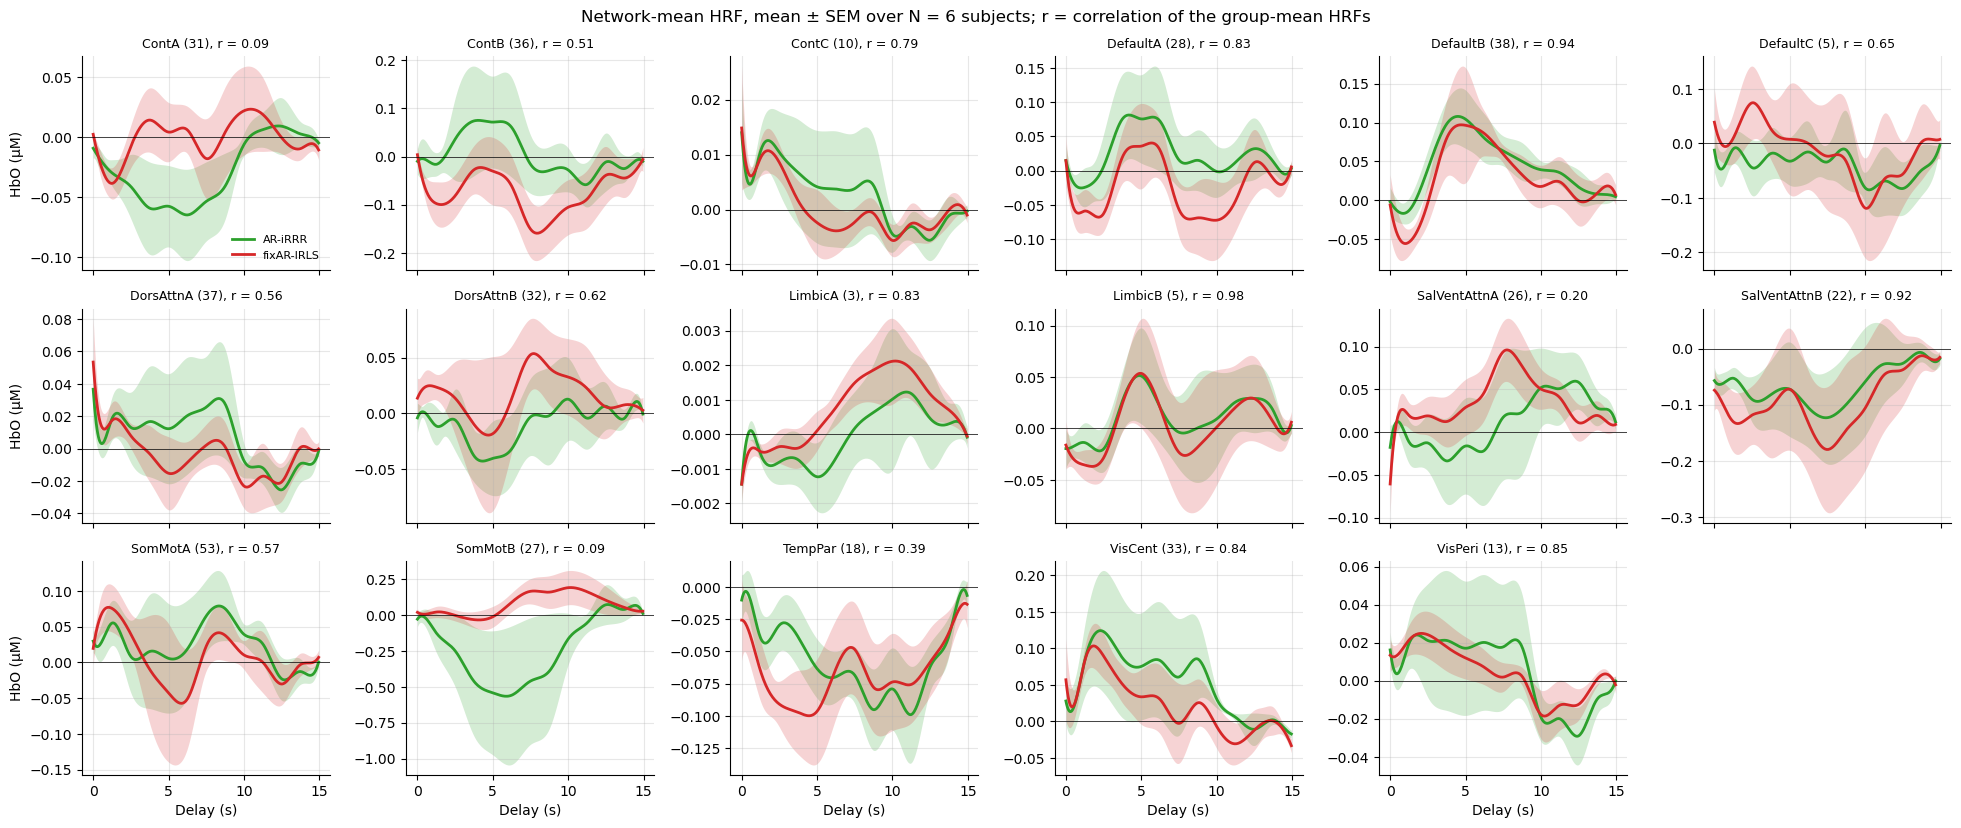

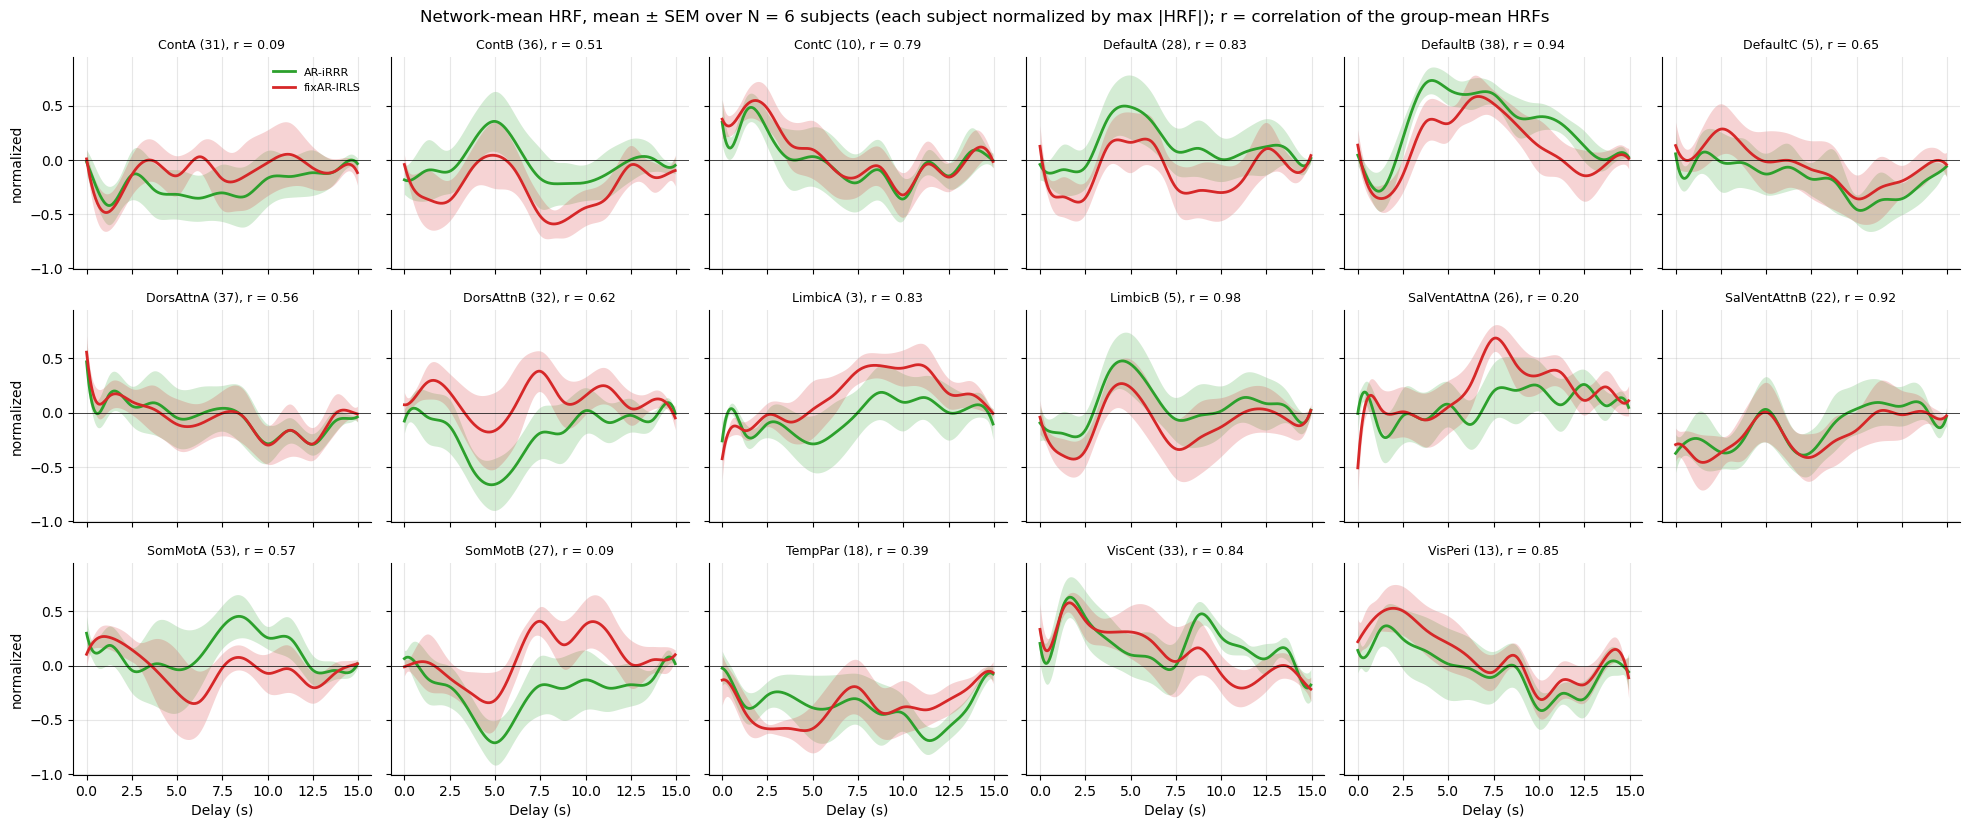

In [4]:
def network_hrf(m, net):
    idx = network_of.index[network_of == net]
    return np.stack([res[s][m]['hrf'].sel(parcel=idx).mean('parcel').values for s in subjects]) * to_uM

h_net = {net: {m: network_hrf(m, net) for m in models} for net in networks}
n_col = 6
n_row = int(np.ceil(len(networks) / n_col))
for normalize in [False, True]:
    fig, axes = plt.subplots(n_row, n_col, figsize=(3.3 * n_col, 2.8 * n_row), sharex=True, sharey=normalize)
    for ax, net in zip(axes.flat, networks):
        for m in models:
            h = h_net[net][m]
            if normalize:
                h = h / np.abs(h).max(1, keepdims=True)
            plot_mean_sem(ax, h, m)
        r = np.corrcoef(h_net[net]['AR-iRRR'].mean(0), h_net[net]['fixAR-IRLS'].mean(0))[0, 1]
        ax.set_title(f'{net} ({n_parcel[net]}), r = {r:.2f}', fontsize=9)
        style(ax)
    for ax in axes.flat[len(networks):]:
        ax.axis('off')
    for ax in axes[-1]:
        ax.set_xlabel('Delay (s)')
    for ax in axes[:, 0]:
        ax.set_ylabel('normalized' if normalize else f'{select_chromo} (µM)')
    axes.flat[0].legend(frameon=False, fontsize=8)
    fig.suptitle(f'Network-mean HRF, mean ± SEM over N = {len(subjects)} subjects'
                 + (' (each subject normalized by max |HRF|)' if normalize else '')
                 + '; r = correlation of the group-mean HRFs')
    fig.tight_layout()
    fig.savefig(os.path.join(fig_dir, f'hrf_networks{"_normalized" if normalize else ""}.png'), dpi=150)
    plt.show()

## 5. Agreement between models per network

For every subject and parcel:
- **shape**: Pearson `r` between the AR-iRRR and fixAR-IRLS HRFs over the delay axis;
- **amplitude**: RMS(AR-iRRR HRF) / RMS(fixAR-IRLS HRF), i.e. how much the rank-2 penalty shrinks the HRF.

Boxes pool parcels across subjects; dots are per-subject medians.

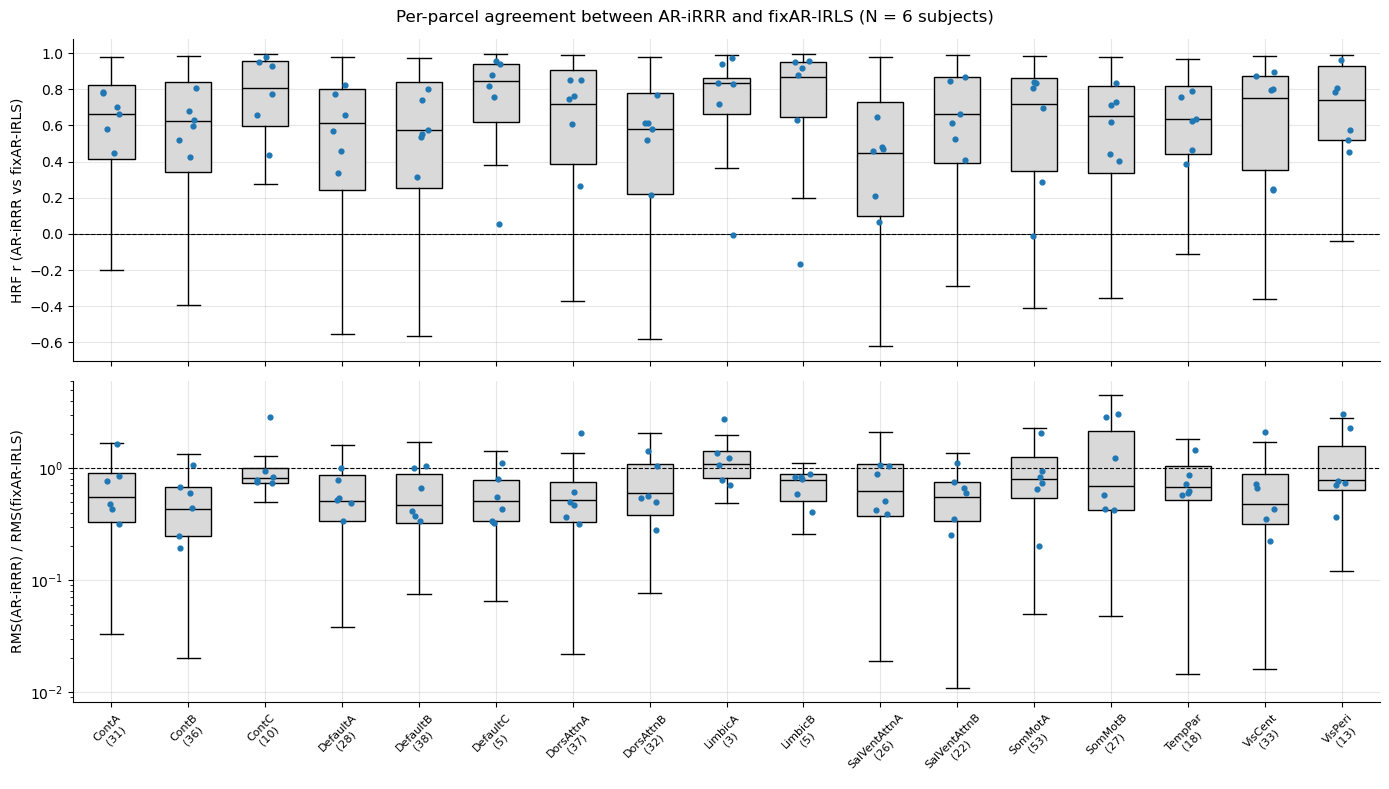

,n parcels,r,RMS ratio,median λ₁
network,,,,
ContA,31,0.66,0.55,0.0032
ContB,36,0.62,0.43,0.0024
ContC,10,0.81,0.82,0.00056
DefaultA,28,0.62,0.51,0.0028
DefaultB,38,0.57,0.46,0.0032
DefaultC,5,0.84,0.51,0.00078
DorsAttnA,37,0.72,0.52,0.0028
DorsAttnB,32,0.58,0.60,0.0024
LimbicA,3,0.83,1.09,0.0001


all parcels: median r = 0.66, median RMS ratio = 0.60


In [5]:
rows = []
for s in subjects:
    a = res[s]['AR-iRRR']['hrf'].values
    b = res[s]['fixAR-IRLS']['hrf'].values
    a_c, b_c = a - a.mean(1, keepdims=True), b - b.mean(1, keepdims=True)
    r = (a_c * b_c).sum(1) / np.sqrt((a_c ** 2).sum(1) * (b_c ** 2).sum(1))
    ratio = np.sqrt((a ** 2).mean(1)) / np.sqrt((b ** 2).mean(1))
    rows.append(pd.DataFrame({'subject': s, 'parcel': parcels, 'network': network_of.values, 'r': r, 'RMS ratio': ratio}))
agree = pd.concat(rows, ignore_index=True)
subj_med = agree.groupby(['network', 'subject'])[['r', 'RMS ratio']].median().reset_index()

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
rng = np.random.default_rng(0)
for ax, col, ref in [(axes[0], 'r', 0), (axes[1], 'RMS ratio', 1)]:
    vals = [agree.loc[agree.network == n, col].values for n in networks]
    bp = ax.boxplot(vals, showfliers=False, widths=0.6, patch_artist=True, medianprops={'color': 'k'})
    for box in bp['boxes']:
        box.set_facecolor('0.85')
    for i, n in enumerate(networks):
        v = subj_med.loc[subj_med.network == n, col].values
        ax.scatter(np.full(len(v), i + 1) + rng.uniform(-0.12, 0.12, len(v)), v, s=12, color='C0', zorder=3)
    ax.axhline(ref, color='k', lw=0.8, ls='--')
    style(ax)
axes[0].set_ylabel('HRF r (AR-iRRR vs fixAR-IRLS)')
axes[1].set_ylabel('RMS(AR-iRRR) / RMS(fixAR-IRLS)')
axes[1].set_yscale('log')
axes[1].set_xticks(range(1, len(networks) + 1), [f'{n}\n({n_parcel[n]})' for n in networks], fontsize=8, rotation=45)
fig.suptitle(f'Per-parcel agreement between AR-iRRR and fixAR-IRLS (N = {len(subjects)} subjects)')
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, 'agreement_by_network.png'), dpi=150)
plt.show()

summ = agree.groupby('network')[['r', 'RMS ratio']].median().loc[networks]
summ.insert(0, 'n parcels', n_parcel)
summ['median λ₁'] = lam.astype(float).median()
display(summ.style.format({'r': '{:.2f}', 'RMS ratio': '{:.2f}', 'median λ₁': '{:.2g}'})
        .background_gradient(cmap='RdBu_r', vmin=-1, vmax=1, subset=['r']))
print(f"all parcels: median r = {agree.r.median():.2f}, median RMS ratio = {agree['RMS ratio'].median():.2f}")

## 6. fixAR-IRLS F test

Per parcel, the F test of all 15 B-spline coefficients = 0 (does the Cz EEG regressor explain variance in HbO?). The plot shows the fraction of parcels with p < 0.05 per network and subject (uncorrected; 0.05 is the chance level). AR-iRRR has no test statistics.

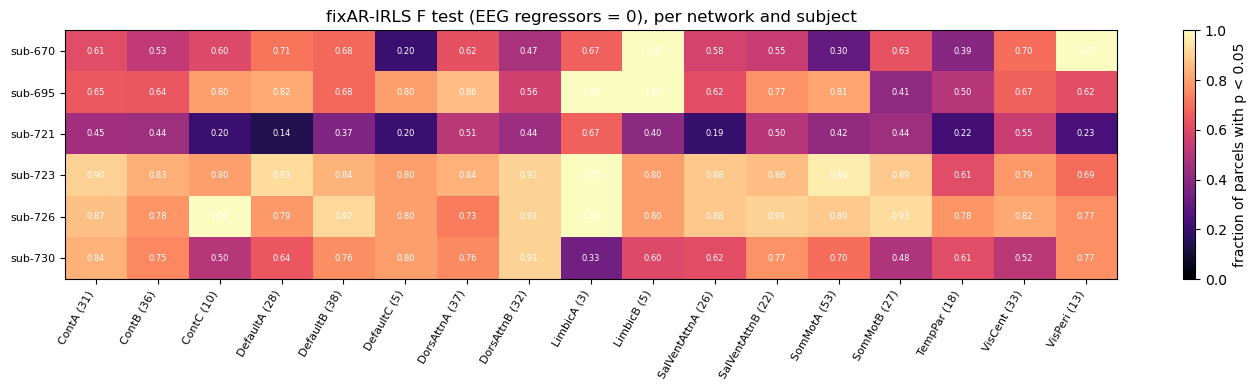

fraction of all parcels with p < 0.05: 0.677 (chance 0.05)
DefaultA_PFCd_1_LH: p = {'sub-670': 0.22, 'sub-695': 0.0, 'sub-721': 0.147, 'sub-723': 0.0, 'sub-726': 0.0, 'sub-730': 0.0}


In [6]:
pvals = pd.DataFrame({s: {p: float(res[s]['fixAR-IRLS']['stats']['f_test_full_noEEG'][p].pvalue) for p in parcels}
                      for s in subjects})
frac_sig = (pvals < 0.05).groupby(network_of).mean().loc[networks]

fig, ax = plt.subplots(figsize=(14, 4))
im = ax.imshow(frac_sig.T.values, aspect='auto', cmap='magma', vmin=0, vmax=max(0.2, frac_sig.values.max()))
ax.set_xticks(range(len(networks)), [f'{n} ({n_parcel[n]})' for n in networks], rotation=60, ha='right', fontsize=8)
ax.set_yticks(range(len(subjects)), subjects, fontsize=8)
for i in range(len(subjects)):
    for j in range(len(networks)):
        ax.text(j, i, f'{frac_sig.values[j, i]:.2f}', ha='center', va='center', fontsize=6, color='w')
fig.colorbar(im, ax=ax, label='fraction of parcels with p < 0.05')
ax.set_title('fixAR-IRLS F test (EEG regressors = 0), per network and subject')
fig.tight_layout()
fig.savefig(os.path.join(fig_dir, 'ftest_frac_sig.png'), dpi=150)
plt.show()
print(f"fraction of all parcels with p < 0.05: {(pvals < 0.05).values.mean():.3f} (chance 0.05)")
print(f"{plot_parcel}: p =", pvals.loc[plot_parcel].round(3).to_dict())

## 7. Summary (N = 6 subjects)

- **λ₁**: every network reaches rank 2. Large networks (18–53 parcels) select λ₁ ≈ 2–3·10⁻³; small ones (ContC, DefaultC, LimbicA/B, VisPeri) need 10⁻⁴–6·10⁻⁴.
- **Shape agreement**: median per-parcel r = 0.66. It is highest in the small networks (ContC, DefaultC, LimbicA/B, VisPeri; median r ≈ 0.75–0.87), where rank 2 is close to the number of parcels and iRRR is nearly unconstrained. It is lowest in SalVentAttnA (≈ 0.45). At the group level, the network-mean HRFs agree well in DefaultA/B, LimbicB, SalVentAttnB, VisCent and VisPeri (r ≥ 0.83), and poorly in ContA, SomMotB and SalVentAttnA (r ≤ 0.2).
- **Amplitude**: median RMS(AR-iRRR) / RMS(fixAR-IRLS) = 0.60, so the rank-2 penalty shrinks most parcels' HRFs, except in the 3-parcel LimbicA. Some parcels have ratios > 1; these are parcels where the shared network components put more weight than their own IRLS fit. SomMotB, where the AR-iRRR group mean is a large negative dip, is driven by such parcels in a couple of subjects.
- **Plot parcel** (`DefaultA_PFCd_1_LH`): AR-iRRR gives a much flatter, smoother group HRF than fixAR-IRLS. The per-subject agreement varies from r = −0.09 (sub-695) to 0.86 (sub-723).
- **fixAR-IRLS F test**: 68% of parcels have p < 0.05 for the EEG regressors (chance 5%). This is either a strong EEG–HbO coupling or anti-conservative SEs from a whitening kernel shared across the network's parcels, so treat it with caution.
